<a href="https://colab.research.google.com/github/radhishmahajan/AI_Sales_Forecast/blob/main/RetailIQ_UCI_Online_Retail_Full_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RetailIQ — AI Sales Forecasting & Inventory Optimization



In [ ]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn joblib openpyxl pyarrow


In [ ]:
import json, math, warnings, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

PROJECT_DIR = Path("/content/sales_forecasting_inventory")
RAW_DIR = PROJECT_DIR / "backend" / "data" / "raw"
ARTIFACT_DIR = PROJECT_DIR / "backend" / "artifacts"
RAW_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
print("Artifacts will be saved to:", ARTIFACT_DIR)

Artifacts will be saved to: /content/sales_forecasting_inventory/backend/artifacts


In [ ]:
from google.colab import files
uploaded = files.upload()

excel_file = next((name for name in uploaded if name.lower().endswith((".xlsx", ".xls"))), None)
if excel_file is None:
    raise ValueError("Please upload the UCI Excel file: Online Retail.xlsx")


raw = pd.read_excel(excel_file, engine="openpyxl")


print("Loaded file:", excel_file)
print("Dataset shape:", raw.shape)
display(raw.head())


Saving Online Retail.xlsx to Online Retail.xlsx
Loaded file: Online Retail.xlsx
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.550,"17,850.000",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.750,"17,850.000",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom


In [ ]:
EXPECTED = ["InvoiceNo","StockCode","Description","Quantity","InvoiceDate","UnitPrice","CustomerID","Country"]
missing = set(EXPECTED) - set(raw.columns)
assert not missing, f"Unexpected dataset schema. Missing columns: {missing}"
raw = raw[EXPECTED].copy()
raw.to_csv(RAW_DIR / "Online Retail.csv", index=False)
print(f"Rows: {len(raw):,} | Columns: {len(raw.columns)}")

Rows: 541,909 | Columns: 8


In [ ]:
display(raw.head(10))
display(raw.dtypes.to_frame("dtype"))
missing = raw.isna().sum().to_frame("missing_rows")
missing["missing_percent"] = (missing["missing_rows"] / len(raw) * 100).round(2)
display(missing)
print("Exact duplicate rows:", raw.duplicated().sum())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.550,"17,850.000",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.750,"17,850.000",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.650,"17,850.000",United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.250,"17,850.000",United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.850,"17,850.000",United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.850,"17,850.000",United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.690,"13,047.000",United Kingdom


,dtype
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object


,missing_rows,missing_percent
InvoiceNo,0,0.000
StockCode,0,0.000
Description,1454,0.270
Quantity,0,0.000
InvoiceDate,0,0.000
UnitPrice,0,0.000
CustomerID,135080,24.930
Country,0,0.000


Exact duplicate rows: 5268


In [ ]:
audit = {
    "rows": len(raw),
    "unique_invoices": raw["InvoiceNo"].nunique(dropna=True),
    "unique_products": raw["StockCode"].nunique(dropna=True),
    "unique_countries": raw["Country"].nunique(dropna=True),
    "cancelled_invoice_rows": raw["InvoiceNo"].astype(str).str.startswith("C").sum(),
    "nonpositive_quantity_rows": (pd.to_numeric(raw["Quantity"], errors="coerce") <= 0).sum(),
    "nonpositive_price_rows": (pd.to_numeric(raw["UnitPrice"], errors="coerce") <= 0).sum(),
    "date_min": str(pd.to_datetime(raw["InvoiceDate"], errors="coerce").min()),
    "date_max": str(pd.to_datetime(raw["InvoiceDate"], errors="coerce").max())
}
display(pd.Series(audit, name="value").to_frame())

,value
rows,541909
unique_invoices,25900
unique_products,4070
unique_countries,38
cancelled_invoice_rows,9288
nonpositive_quantity_rows,10624
nonpositive_price_rows,2517
date_min,2010-12-01 08:26:00
date_max,2011-12-09 12:50:00


In [ ]:
df = raw.copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
df["StockCode"] = df["StockCode"].astype(str).str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

rows_before = len(df)
df = df[~df["InvoiceNo"].str.upper().str.startswith("C")]
df = df.dropna(subset=["StockCode","InvoiceDate","Quantity","UnitPrice"])
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df = df[df["StockCode"].ne("") & df["StockCode"].str.lower().ne("nan")]
df = df.drop_duplicates()
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
df["Date"] = df["InvoiceDate"].dt.normalize()
df = df.sort_values("InvoiceDate").reset_index(drop=True)

print(f"Before cleaning: {rows_before:,}")
print(f"After cleaning : {len(df):,}")
print(f"Removed        : {rows_before-len(df):,}")
print("Date range:", df.Date.min().date(), "to", df.Date.max().date())
display(df.head())

Before cleaning: 541,909
After cleaning : 524,878
Removed        : 17,031
Date range: 2010-12-01 to 2011-12-09


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Date
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.550,"17,850.000",United Kingdom,15.300,2010-12-01
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom,20.340,2010-12-01
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.750,"17,850.000",United Kingdom,22.000,2010-12-01
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom,20.340,2010-12-01
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom,20.340,2010-12-01


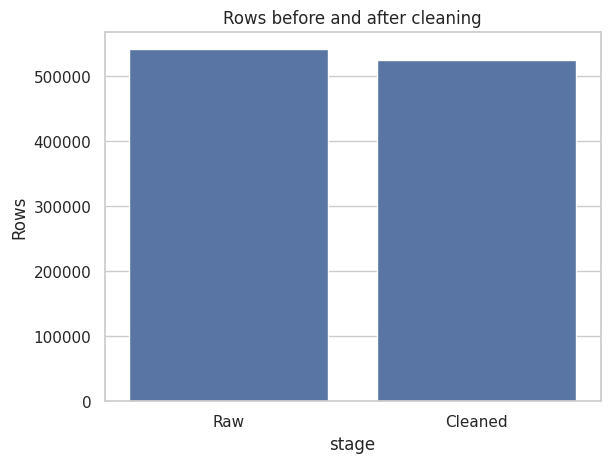

In [ ]:
clean_summary = pd.DataFrame({"stage":["Raw","Cleaned"],"rows":[len(raw),len(df)]})
sns.barplot(data=clean_summary, x="stage", y="rows")
plt.title("Rows before and after cleaning")
plt.ylabel("Rows")
plt.show()

## Exploratory Data Analysis



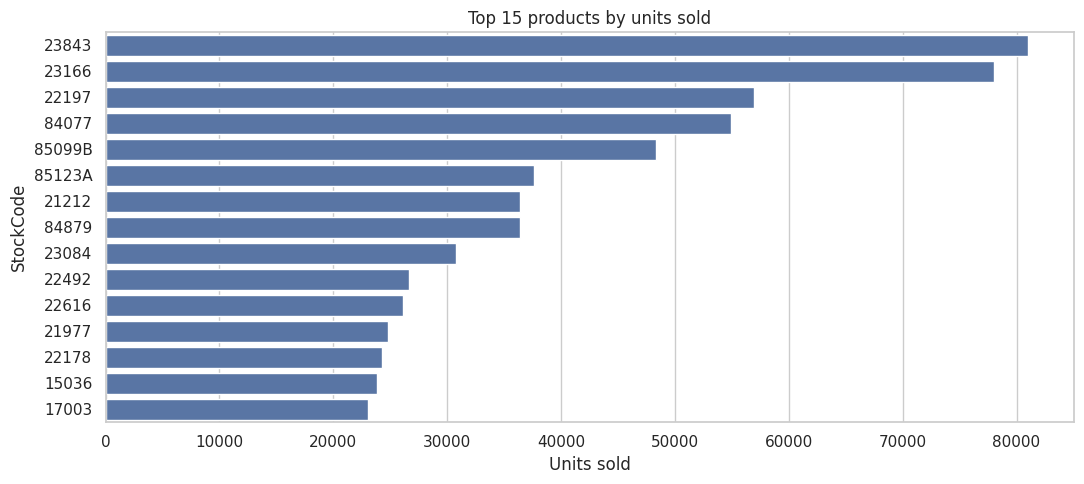

,StockCode,Quantity
0,23843,80995
1,23166,78033
2,22197,56898
3,84077,54951
4,85099B,48371
5,85123A,37641
6,21212,36396
7,84879,36362
8,23084,30739
9,22492,26633


In [ ]:
top_all = df.groupby("StockCode")["Quantity"].sum().sort_values(ascending=False).head(15).reset_index()
plt.figure(figsize=(11,5))
sns.barplot(data=top_all, y="StockCode", x="Quantity")
plt.title("Top 15 products by units sold")
plt.xlabel("Units sold")
plt.tight_layout()
plt.show()
display(top_all)

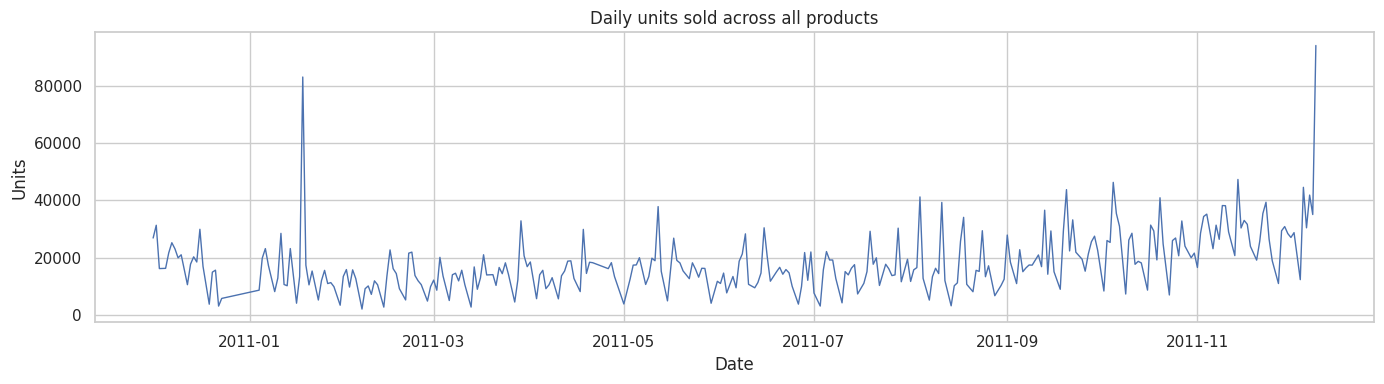

In [ ]:
daily_total = df.groupby("Date", as_index=False).agg(
    units_sold=("Quantity","sum"), revenue=("Revenue","sum"),
    invoices=("InvoiceNo","nunique"))
plt.figure(figsize=(14,4))
plt.plot(daily_total.Date, daily_total.units_sold, linewidth=1)
plt.title("Daily units sold across all products")
plt.xlabel("Date"); plt.ylabel("Units")
plt.tight_layout(); plt.show()

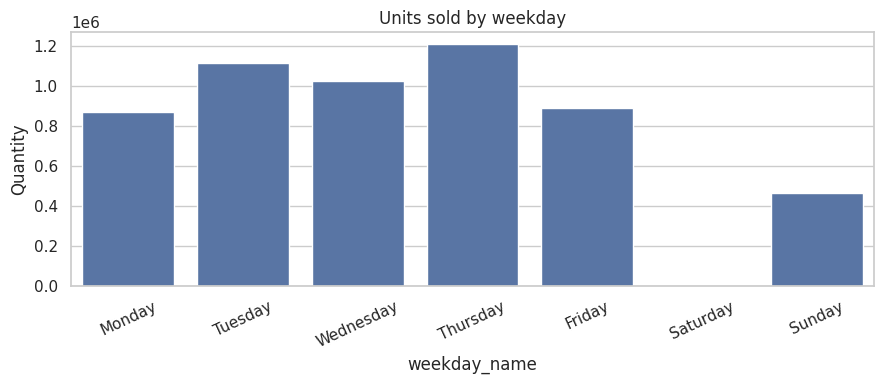

In [ ]:
weekday_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
df["weekday_name"] = df["Date"].dt.day_name()
weekday_sales = df.groupby("weekday_name")["Quantity"].sum().reindex(weekday_order).reset_index()
plt.figure(figsize=(9,4))
sns.barplot(data=weekday_sales, x="weekday_name", y="Quantity")
plt.title("Units sold by weekday")
plt.xticks(rotation=25); plt.tight_layout(); plt.show()

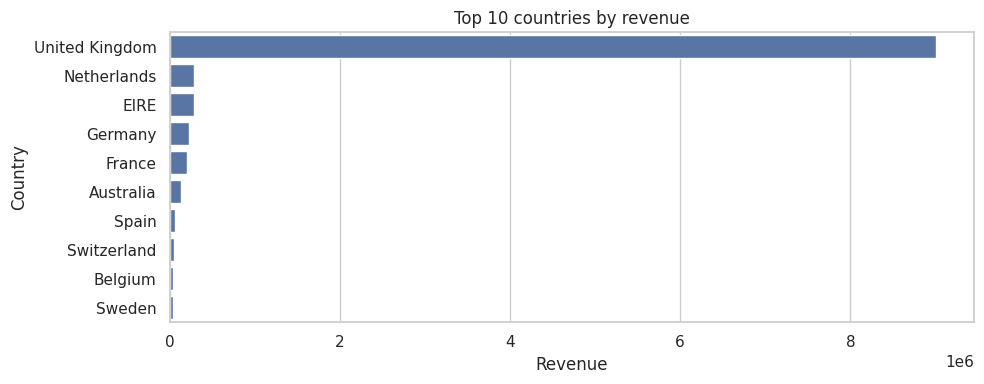

In [ ]:
country_sales = df.groupby("Country")["Revenue"].sum().nlargest(10).reset_index()
plt.figure(figsize=(10,4))
sns.barplot(data=country_sales, y="Country", x="Revenue")
plt.title("Top 10 countries by revenue")
plt.tight_layout(); plt.show()

In [ ]:
TOP_N_PRODUCTS = 40
product_totals = df.groupby("StockCode")["Quantity"].sum().sort_values(ascending=False)
selected_skus = product_totals.head(TOP_N_PRODUCTS).index.astype(str).tolist()
df_model = df[df["StockCode"].isin(selected_skus)].copy()

description_map = (
    df_model.dropna(subset=["Description"]).groupby("StockCode")["Description"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else str(x.iloc[-1])).to_dict()
)
daily_demand = df_model.groupby(["StockCode","Date"], as_index=False).agg(
    demand=("Quantity","sum"), revenue=("Revenue","sum"))

all_dates = pd.date_range(daily_demand.Date.min(), daily_demand.Date.max(), freq="D")
parts = []
for sku in selected_skus:
    one = daily_demand[daily_demand.StockCode == sku].set_index("Date").reindex(all_dates)
    one.index.name = "Date"
    one["StockCode"] = sku
    one["demand"] = one["demand"].fillna(0.0)
    one["revenue"] = one["revenue"].fillna(0.0)
    parts.append(one.reset_index())

panel = pd.concat(parts, ignore_index=True)
panel["Description"] = panel["StockCode"].map(description_map).fillna("Unknown product")
daily_price = df_model.groupby(["StockCode","Date"])["UnitPrice"].median().rename("observed_price").reset_index()
panel = panel.merge(daily_price, on=["StockCode","Date"], how="left")
panel = panel.sort_values(["StockCode","Date"]).reset_index(drop=True)

print("Daily panel rows:", f"{len(panel):,}")
print("Unique products:", panel.StockCode.nunique())
display(panel.head())

Daily panel rows: 14,960
Unique products: 40


,Date,StockCode,demand,revenue,Description,observed_price
0,2010-12-01,15036,0.000,0.000,ASSORTED COLOURS SILK FAN,NaN
1,2010-12-02,15036,48.000,36.000,ASSORTED COLOURS SILK FAN,0.750
2,2010-12-03,15036,15.000,12.840,ASSORTED COLOURS SILK FAN,1.015
3,2010-12-04,15036,0.000,0.000,ASSORTED COLOURS SILK FAN,NaN
4,2010-12-05,15036,12.000,9.000,ASSORTED COLOURS SILK FAN,0.750


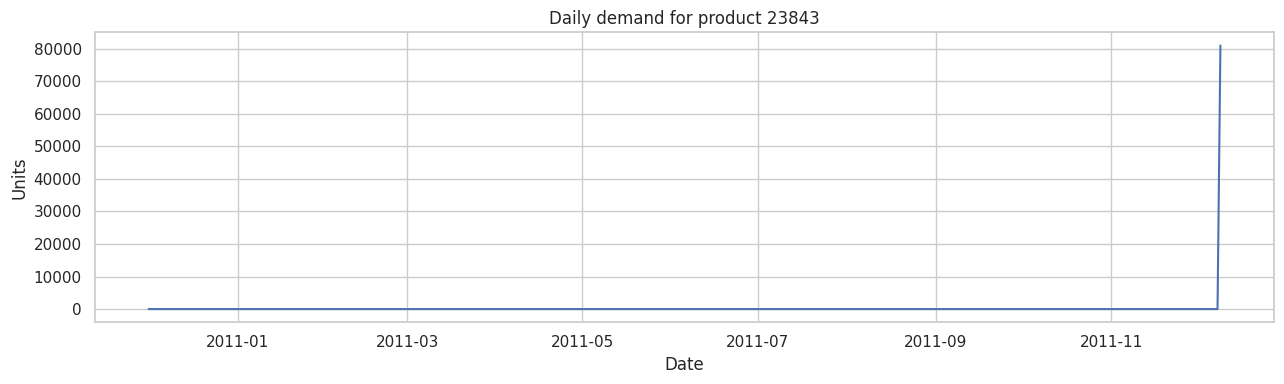

In [ ]:
example_sku = selected_skus[0]
example = panel[panel.StockCode == example_sku]
plt.figure(figsize=(13,4))
plt.plot(example.Date, example.demand)
plt.title(f"Daily demand for product {example_sku}")
plt.xlabel("Date"); plt.ylabel("Units")
plt.tight_layout(); plt.show()

##Feature engineering



In [ ]:
def make_features(daily_panel):
    outputs = []
    for sku, group in daily_panel.groupby("StockCode", sort=False):
        g = group.sort_values("Date").copy()
        demand = g["demand"].astype(float)


        g["lag_1"] = demand.shift(1)
        g["lag_7"] = demand.shift(7)
        g["lag_14"] = demand.shift(14)
        prior = demand.shift(1)
        g["rolling_mean_7"] = prior.rolling(7, min_periods=7).mean()
        g["rolling_std_7"] = prior.rolling(7, min_periods=7).std()
        g["rolling_mean_28"] = prior.rolling(28, min_periods=14).mean()


        g["unit_price"] = g["observed_price"].ffill().shift(1)
        g["price_change_pct"] = g["unit_price"].pct_change().replace([np.inf,-np.inf], np.nan)


        g["day_of_week"] = g["Date"].dt.dayofweek
        g["month"] = g["Date"].dt.month
        g["day_of_month"] = g["Date"].dt.day
        g["is_weekend"] = (g["day_of_week"] >= 5).astype(int)


        g["target_next_day_demand"] = demand
        outputs.append(g)

    result = pd.concat(outputs, ignore_index=True)
    required = ["lag_1","lag_7","lag_14","rolling_mean_7","rolling_mean_28","unit_price"]
    result = result.dropna(subset=required).copy()
    result = result.replace([np.inf,-np.inf], np.nan)
    result["price_change_pct"] = result["price_change_pct"].fillna(0)
    return result.sort_values(["Date","StockCode"]).reset_index(drop=True)

supervised = make_features(panel)
print("Supervised rows:", f"{len(supervised):,}")
display(supervised[["StockCode","Date","lag_1","lag_7","lag_14","rolling_mean_7",
                    "rolling_std_7","rolling_mean_28","unit_price","price_change_pct",
                    "day_of_week","is_weekend","target_next_day_demand"]].head(10))

Supervised rows: 13,597


,StockCode,Date,lag_1,lag_7,lag_14,rolling_mean_7,rolling_std_7,rolling_mean_28,unit_price,price_change_pct,day_of_week,is_weekend,target_next_day_demand
0,15036,2010-12-15,12.000,13.000,0.000,4.714,5.529,8.000,0.750,-0.414,2,0,0.000
1,17003,2010-12-15,0.000,0.000,39.000,13.143,17.780,77.000,0.430,0.000,2,0,36.000
2,20724,2010-12-15,105.000,47.000,4.000,46.429,46.957,36.286,0.850,-0.488,2,0,21.000
3,20725,2010-12-15,36.000,117.000,78.000,39.286,37.371,40.000,1.650,0.000,2,0,59.000
4,21212,2010-12-15,188.000,134.000,241.000,131.857,170.702,164.286,0.550,0.000,2,0,194.000
5,21213,2010-12-15,69.000,73.000,51.000,31.000,36.824,31.571,0.550,-0.570,2,0,24.000
6,21731,2010-12-15,61.000,37.000,483.000,27.714,25.191,65.500,1.650,-0.341,2,0,10.000
7,21790,2010-12-15,60.000,196.000,41.000,60.429,73.091,61.571,0.850,-0.488,2,0,0.000
8,21915,2010-12-15,126.000,0.000,101.000,40.286,45.324,147.286,1.250,-0.502,2,0,12.000
9,21931,2010-12-15,72.000,101.000,54.000,37.286,36.482,31.714,1.950,0.000,2,0,32.000


In [ ]:
display(supervised[supervised.StockCode == selected_skus[0]][
    ["Date","target_next_day_demand","lag_1","lag_7","rolling_mean_7","rolling_std_7","rolling_mean_28"]
].head(12))

,Date,target_next_day_demand,lag_1,lag_7,rolling_mean_7,rolling_std_7,rolling_mean_28


In [ ]:
TEST_DAYS = 60
supervised = supervised.sort_values("Date").copy()
test_start = supervised.Date.max() - pd.Timedelta(days=TEST_DAYS-1)
train_df = supervised[supervised.Date < test_start].copy()
test_df = supervised[supervised.Date >= test_start].copy()

print("Train:", train_df.Date.min().date(), "to", train_df.Date.max().date(), "| rows:", len(train_df))
print("Test :", test_df.Date.min().date(), "to", test_df.Date.max().date(), "| rows:", len(test_df))
assert train_df.Date.max() < test_df.Date.min()
assert len(train_df) and len(test_df)

Train: 2010-12-15 to 2011-10-10 | rows: 11257
Test : 2011-10-11 to 2011-12-09 | rows: 2340


In [ ]:
CATEGORICAL_FEATURES = ["StockCode"]
NUMERIC_FEATURES = [
    "lag_1","lag_7","lag_14","rolling_mean_7","rolling_std_7","rolling_mean_28",
    "unit_price","price_change_pct","day_of_week","month","day_of_month","is_weekend"
]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
TARGET = "target_next_day_demand"

X_train, y_train = train_df[FEATURES].copy(), train_df[TARGET].astype(float)
X_test, y_test = test_df[FEATURES].copy(), test_df[TARGET].astype(float)

def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.maximum(np.asarray(y_pred, dtype=float), 0)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    denom = np.abs(y_true).sum()
    wape = np.abs(y_true-y_pred).sum()/denom*100 if denom else np.nan
    return {"MAE":float(mae), "RMSE":float(rmse), "WAPE_percent":float(wape)}

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

Train shape: (11257, 13) | Test shape: (2340, 13)


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("sku", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
        ("numeric", SimpleImputer(strategy="median"), NUMERIC_FEATURES)
    ],
    remainder="drop",
    sparse_threshold=0
)

candidate_models = {
    "RandomForest": RandomForestRegressor(
        n_estimators=250, max_depth=18, min_samples_leaf=2,
        random_state=SEED, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=180, learning_rate=0.08, max_leaf_nodes=20,
        l2_regularization=1.0, random_state=SEED
    )
}

results = {"NaiveBaseline": calculate_metrics(y_test, test_df["lag_1"].to_numpy())}
fitted_models, predictions = {}, {}

for name, estimator in candidate_models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = np.maximum(pipe.predict(X_test), 0)
    fitted_models[name] = pipe
    predictions[name] = pred
    results[name] = calculate_metrics(y_test, pred)

results_df = pd.DataFrame(results).T.sort_values("MAE")
display(results_df.round(3))

,MAE,RMSE,WAPE_percent
HistGradientBoosting,74.592,206.677,84.006
RandomForest,75.410,201.006,84.927
NaiveBaseline,104.659,276.325,117.867


In [ ]:
best_model_name = min(fitted_models, key=lambda name: results[name]["MAE"])
best_model = fitted_models[best_model_name]
best_predictions = predictions[best_model_name]
print("Best ML model by test MAE:", best_model_name)
print("Metrics:", results[best_model_name])

Best ML model by test MAE: HistGradientBoosting
Metrics: {'MAE': 74.5919882289647, 'RMSE': 206.67713331594484, 'WAPE_percent': 84.00564663043123}


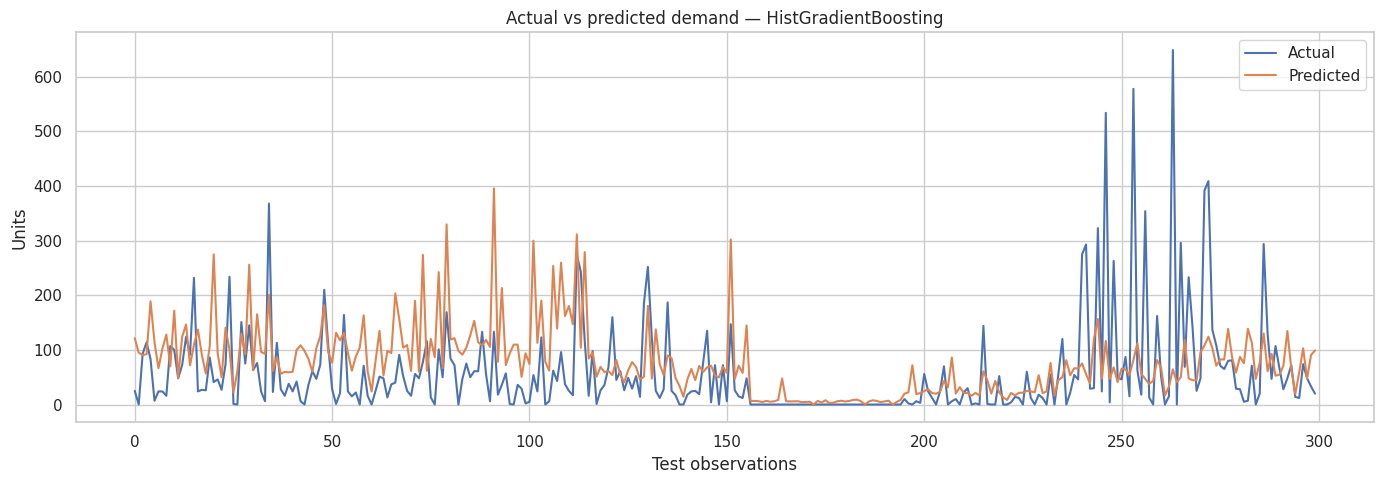

In [ ]:
plot_data = test_df[["Date","StockCode",TARGET]].copy()
plot_data["prediction"] = best_predictions
plot_data = plot_data.sort_values("Date").head(300)

plt.figure(figsize=(14,5))
plt.plot(plot_data[TARGET].to_numpy(), label="Actual")
plt.plot(plot_data["prediction"].to_numpy(), label="Predicted")
plt.title(f"Actual vs predicted demand — {best_model_name}")
plt.xlabel("Test observations"); plt.ylabel("Units")
plt.legend(); plt.tight_layout(); plt.show()

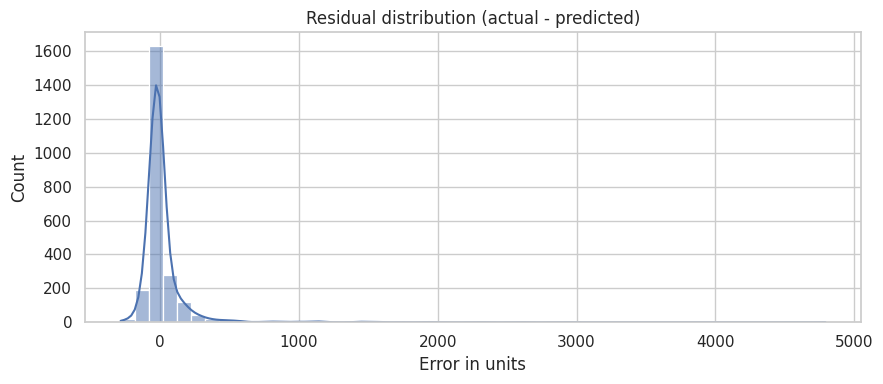

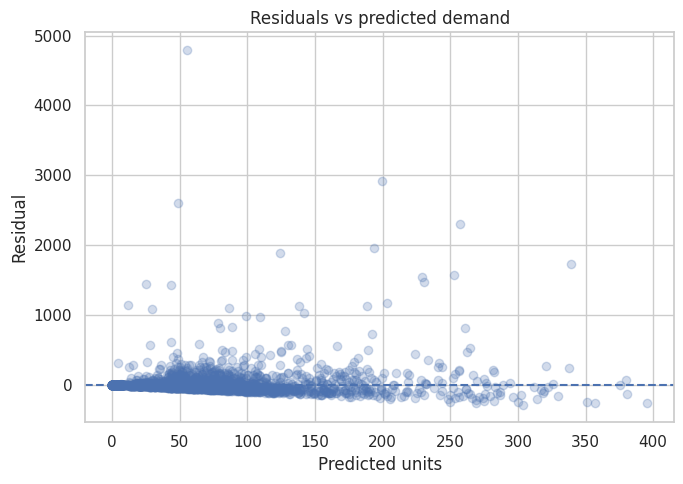

In [ ]:
residuals = y_test.to_numpy() - best_predictions
plt.figure(figsize=(9,4))
sns.histplot(residuals, bins=50, kde=True)
plt.title("Residual distribution (actual - predicted)")
plt.xlabel("Error in units"); plt.tight_layout(); plt.show()

plt.figure(figsize=(7,5))
plt.scatter(best_predictions, residuals, alpha=0.25)
plt.axhline(0, linestyle="--")
plt.title("Residuals vs predicted demand")
plt.xlabel("Predicted units"); plt.ylabel("Residual")
plt.tight_layout(); plt.show()

In [ ]:
test_eval = test_df.copy()
test_eval["prediction"] = best_predictions
per_sku = []
for sku, group in test_eval.groupby("StockCode"):
    m = calculate_metrics(group[TARGET], group["prediction"])
    per_sku.append({"StockCode":sku, **m, "test_rows":len(group)})
per_product_metrics = pd.DataFrame(per_sku).sort_values("WAPE_percent")
display(per_product_metrics.head(10))
display(per_product_metrics.tail(10))

,StockCode,MAE,RMSE,WAPE_percent,test_rows
11,22086,113.862,197.822,56.742,60
17,22423,22.090,29.391,61.703,60
33,84946,53.090,74.489,61.948,60
2,20724,45.593,63.175,63.855,60
3,20725,37.013,48.535,65.587,60
38,85123A,81.291,170.772,68.687,60
23,22952,94.098,148.831,68.693,60
32,84879,100.971,186.793,70.054,60
28,23203,69.754,140.579,71.213,60
35,85099B,117.777,186.943,73.244,60


,StockCode,MAE,RMSE,WAPE_percent,test_rows
16,22386,67.721,98.071,115.073,60
34,84991,57.020,87.396,117.527,60
29,47566,29.400,48.023,119.433,60
1,17003,73.138,194.942,131.820,60
10,21977,48.273,59.740,133.907,60
12,22151,34.695,43.409,141.422,60
31,84755,37.895,50.361,155.307,60
37,85099F,48.619,65.031,157.173,60
26,23166,29.460,45.837,168.341,60
0,15036,49.509,62.220,259.435,60


,feature,importance
44,numeric__rolling_mean_28,0.167
42,numeric__rolling_mean_7,0.107
43,numeric__rolling_std_7,0.099
49,numeric__day_of_month,0.090
40,numeric__lag_7,0.083
41,numeric__lag_14,0.080
48,numeric__month,0.064
39,numeric__lag_1,0.063
47,numeric__day_of_week,0.062
45,numeric__unit_price,0.040


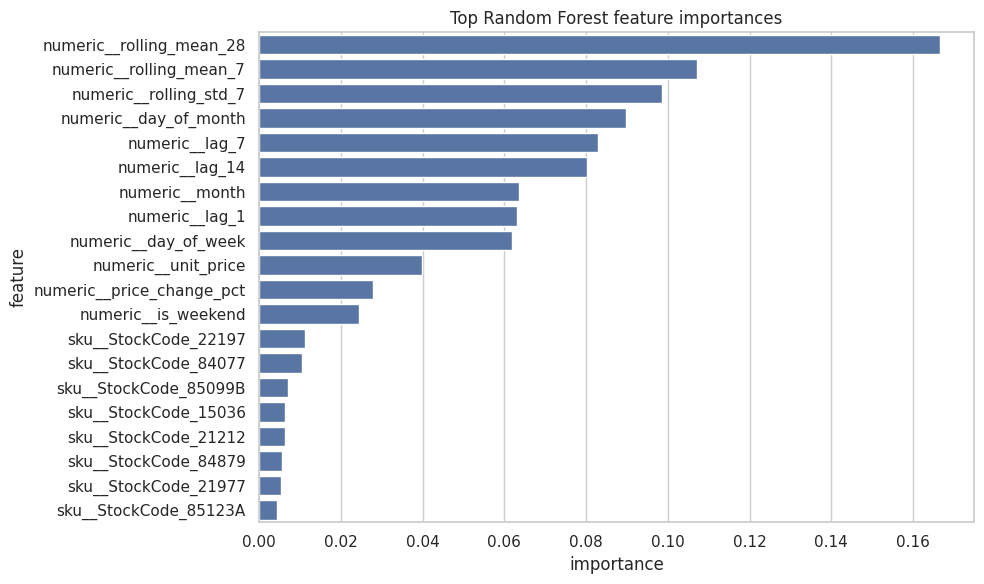

In [ ]:
if "RandomForest" in fitted_models:
    rf_pipe = fitted_models["RandomForest"]
    prep = rf_pipe.named_steps["preprocessor"]
    rf = rf_pipe.named_steps["model"]
    names = prep.get_feature_names_out()
    importance = pd.DataFrame({"feature":names, "importance":rf.feature_importances_})
    importance = importance.sort_values("importance", ascending=False).head(20)
    display(importance)
    plt.figure(figsize=(10,6))
    sns.barplot(data=importance, x="importance", y="feature")
    plt.title("Top Random Forest feature importances")
    plt.tight_layout(); plt.show()

In [ ]:
joblib.dump(best_model, ARTIFACT_DIR / "demand_model.joblib")

panel_save = panel.copy()
panel_save["Date"] = pd.to_datetime(panel_save["Date"])
panel_save.to_parquet(ARTIFACT_DIR / "daily_panel.parquet", index=False)

products_metadata = (
    panel.groupby("StockCode")
    .agg(description=("Description","first"),
         total_units=("demand","sum"),
         avg_daily_demand=("demand","mean"),
         last_price=("observed_price","last"))
    .reset_index()
)
products_metadata["StockCode"] = products_metadata["StockCode"].astype(str)
products_metadata.to_json(ARTIFACT_DIR / "products.json", orient="records", indent=2)

metadata = {
    "best_model":best_model_name,
    "features":FEATURES,
    "numeric_features":NUMERIC_FEATURES,
    "categorical_features":CATEGORICAL_FEATURES,
    "test_start":str(test_df.Date.min().date()),
    "test_end":str(test_df.Date.max().date()),
    "train_rows":int(len(train_df)),
    "test_rows":int(len(test_df)),
    "products":int(panel.StockCode.nunique()),
    "metrics":results,
    "dataset":"UCI Online Retail (Chen, 2015)",
    "target":"daily product unit demand"
}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))

print("Saved files:")
for f in sorted(ARTIFACT_DIR.iterdir()):
    print(f.name, f"{f.stat().st_size:,} bytes")

Saved files:
daily_panel.parquet 84,082 bytes
demand_model.joblib 178,801 bytes
metadata.json 1,232 bytes
products.json 6,739 bytes


In [ ]:

archive = shutil.make_archive("/content/retailiq_artifacts", "zip", ARTIFACT_DIR)
print("Created:", archive)
from google.colab import files
files.download(archive)

Created: /content/retailiq_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def inventory_recommendation(forecast_values, current_stock,
                             lead_time_days=7, review_period_days=7, service_z=1.65):
    values = np.maximum(np.asarray(forecast_values, dtype=float), 0)
    if len(values) == 0:
        raise ValueError("Forecast values cannot be empty.")
    avg = float(values.mean())
    std = float(values.std(ddof=1)) if len(values) > 1 else 0.0
    safety_stock = service_z * std * math.sqrt(max(1, lead_time_days))
    reorder_point = avg * lead_time_days + safety_stock
    target_stock = reorder_point + avg * review_period_days
    order_qty = max(0, math.ceil(target_stock - max(0, current_stock)))
    return {
        "average_daily_forecast":round(avg,2),
        "safety_stock":round(safety_stock,2),
        "reorder_point":round(reorder_point,2),
        "target_stock":round(target_stock,2),
        "current_stock":current_stock,
        "suggested_order_quantity":order_qty,
        "status":"REORDER" if current_stock <= reorder_point else "STOCK_OK"
    }

demo = inventory_recommendation(best_predictions[:14], current_stock=50, lead_time_days=7)
display(pd.Series(demo, name="Illustrative recommendation").to_frame())

,Illustrative recommendation
average_daily_forecast,103.610
safety_stock,255.980
reorder_point,981.260
target_stock,"1,706.550"
current_stock,50
suggested_order_quantity,1657
status,REORDER
